In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
data = fetch_california_housing()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="House_Value")

print("Dataset loaded successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst 5 rows:")
print(X.head())

Dataset loaded successfully!
X shape: (20640, 8)
y shape: (20640,)

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 8)
Testing data: (4128, 8)


In [4]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [5]:
svr_model = SVR(
    kernel="rbf",
    C=100,
    epsilon=0.1
)

print("SVR model created successfully!")

SVR model created successfully!


In [6]:
svr_model.fit(X_train_scaled, y_train)

print("SVR model trained successfully!")

SVR model trained successfully!


In [7]:
svr_pred = svr_model.predict(X_test_scaled)

print("Predictions completed!")
print(svr_pred[:10])

Predictions completed!
[0.4785635  1.37345633 4.81127341 2.45264696 2.95724933 1.55927099
 2.52787264 1.64464261 2.4391984  4.72860305]


In [8]:
svr_mse = mean_squared_error(y_test, svr_pred)
svr_rmse = np.sqrt(svr_mse)
svr_mae = mean_absolute_error(y_test, svr_pred)
svr_r2 = r2_score(y_test, svr_pred)

print("Support Vector Regression Results")
print("-------------------------------")
print("MSE  :", svr_mse)
print("RMSE :", svr_rmse)
print("MAE  :", svr_mae)
print("R2 Score:", svr_r2)

Support Vector Regression Results
-------------------------------
MSE  : 0.3201035236220394
RMSE : 0.5657769203688318
MAE  : 0.37170253158933303
R2 Score: 0.7557224279310508


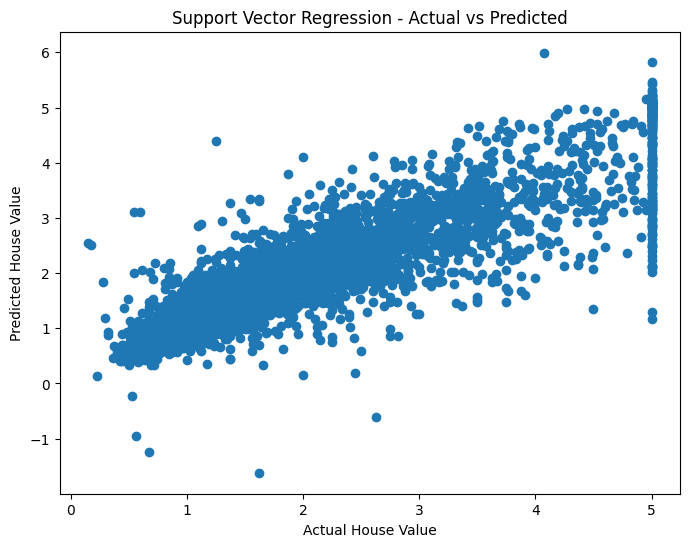

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, svr_pred)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Support Vector Regression - Actual vs Predicted")

plt.show()